# Parsing de los documentos

Antes de elegir un parser se comparan tres sobre las mismas páginas de prueba:

- **PyMuPDF**: lee la capa de texto del PDF con reglas.
- **pdfplumber**: lee la capa de texto con reglas, a partir de la posición de cada carácter.
- **Docling**: usa modelos de aprendizaje automático para detectar el diseño de la página y la estructura de las tablas.

Cada parser se usa con su configuración por defecto, para ver lo que hace sin ajustes.

## Páginas de prueba

Cada página reúne varios retos del corpus:

| Documento | Página del PDF | Qué pone a prueba |
|---|---:|---|
| UNESCO | 45 (impresa 43) | Párrafos con cifras, marcadores de nota en superíndice, notas al pie y una tabla con cifras cuya primera celda ocupa dos líneas |
| INAI | 35 | Tabla de cuatro columnas con celdas largas, guiones de fin de línea y un encabezado con letras espaciadas |
| Iniciativa | 28 | Página escaneada: el texto del PDF viene de un OCR previo que lee los números romanos como `l.`, `11.` y `111.`. También tiene sello y pie de página |

In [1]:
import base64
import html
import time
from pathlib import Path

import fitz  # PyMuPDF
import pdfplumber
from IPython.display import HTML, display

RAW = Path("../data/raw")

## Parsers

Cada función recibe la ruta del PDF y el número de página (empezando en 1). Devuelve el texto, las tablas como listas de filas y el tiempo en segundos.

### PyMuPDF

El texto se extrae con `get_text()` y las tablas con `find_tables()`.

In [2]:
def parse_pymupdf(pdf_path, page_number):
    start = time.perf_counter()
    with fitz.open(pdf_path) as doc:
        page = doc[page_number - 1]
        text = page.get_text()
        tables = [table.extract() for table in page.find_tables().tables]
    return {"text": text, "tables": tables, "seconds": time.perf_counter() - start}

### pdfplumber

El texto se extrae con `extract_text()` y las tablas con `extract_tables()`.

In [3]:
def parse_pdfplumber(pdf_path, page_number):
    start = time.perf_counter()
    with pdfplumber.open(pdf_path) as pdf:
        page = pdf.pages[page_number - 1]
        text = page.extract_text()
        tables = page.extract_tables()
    return {"text": text, "tables": tables, "seconds": time.perf_counter() - start}

### Docling

Docling procesa cada página con un modelo de diseño, que clasifica cada bloque (título, párrafo, tabla, nota al pie, encabezado), y con TableFormer, un modelo que reconstruye la estructura de las tablas. Por defecto también aplica OCR a las imágenes de la página, como las de un documento escaneado. Su salida natural es Markdown.

Los modelos se cargan una sola vez y ese tiempo se mide aparte. La primera ejecución en una computadora también los descarga.

In [4]:
from docling.datamodel.base_models import InputFormat
from docling.document_converter import DocumentConverter

start = time.perf_counter()
converter = DocumentConverter()
converter.initialize_pipeline(InputFormat.PDF)
print(f"Carga de modelos: {time.perf_counter() - start:.2f} s")


def parse_docling(pdf_path, page_number, docling_converter=None):
    docling_converter = docling_converter or converter
    start = time.perf_counter()
    result = docling_converter.convert(pdf_path, page_range=(page_number, page_number))
    text = result.document.export_to_markdown()
    tables = []
    for table in result.document.tables:
        frame = table.export_to_dataframe(doc=result.document)
        tables.append([list(frame.columns)] + frame.values.tolist())
    return {"text": text, "tables": tables, "seconds": time.perf_counter() - start}

C:\Projects\Maestria\PLN\RAG\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

Loading weights:  49%|████▉     | 377/770 [00:00<00:00, 3765.77it/s]

Loading weights: 100%|██████████| 770/770 [00:00<00:00, 5430.36it/s]

Carga de modelos: 4.57 s


## Comparación lado a lado

Para cada página se muestra la imagen y, debajo, una columna por parser con su tiempo, su texto y sus tablas. Una celda marcada como `None` es una celda a la que el parser no asignó contenido. `compare` usa los tres parsers, salvo que se le pase otro conjunto en `parsers`.

Los resultados quedan en `RESULTS`, por archivo y página, para revisarlos después.

In [5]:
PARSERS = {"PyMuPDF": parse_pymupdf, "pdfplumber": parse_pdfplumber, "Docling": parse_docling}
RESULTS = {}
BORDER = "1px solid rgba(128, 128, 128, 0.4)"


def page_image(pdf_path, page_number, dpi=90):
    with fitz.open(pdf_path) as doc:
        png = doc[page_number - 1].get_pixmap(dpi=dpi).tobytes("png")
    return base64.b64encode(png).decode()


def cell_html(value):
    content = '<i style="opacity:0.5">None</i>' if value is None else html.escape(str(value)).replace("\n", "<br>")
    return f'<td style="border:{BORDER}; padding:2px 4px; vertical-align:top">{content}</td>'


def table_html(rows):
    body = "".join("<tr>" + "".join(cell_html(value) for value in row) + "</tr>" for row in rows)
    return f'<table style="border-collapse:collapse; font-size:11px; margin:0 0 8px">{body}</table>'


def compare(file_name, page_number, parsers=None):
    parsers = parsers or PARSERS
    pdf_path = RAW / file_name
    results = {name: parse(pdf_path, page_number) for name, parse in parsers.items()}
    RESULTS.setdefault((file_name, page_number), {}).update(results)

    headers, texts, tables = [], [], []
    for name, result in results.items():
        headers.append(f"<div><b>{name}</b> · {result['seconds']:.2f} s · {len(result['tables'])} tablas</div>")
        texts.append(
            f'<pre style="white-space:pre-wrap; max-height:500px; overflow:auto; margin:0; padding:6px; '
            f'border:{BORDER}; font-size:11px">{html.escape(result["text"])}</pre>'
        )
        tables.append(
            '<div style="overflow:auto">'
            + ("".join(table_html(rows) for rows in result["tables"]) or "<i>Sin tablas</i>")
            + "</div>"
        )

    image = page_image(pdf_path, page_number)
    display(HTML(
        f'<img src="data:image/png;base64,{image}" style="max-width:520px; width:100%; border:{BORDER}">'
        f'<div style="display:grid; grid-template-columns:repeat({len(parsers)}, minmax(0, 1fr)); gap:10px; margin-top:10px">'
        + "".join(headers + texts + tables)
        + "</div>"
    ))

### UNESCO, página 45


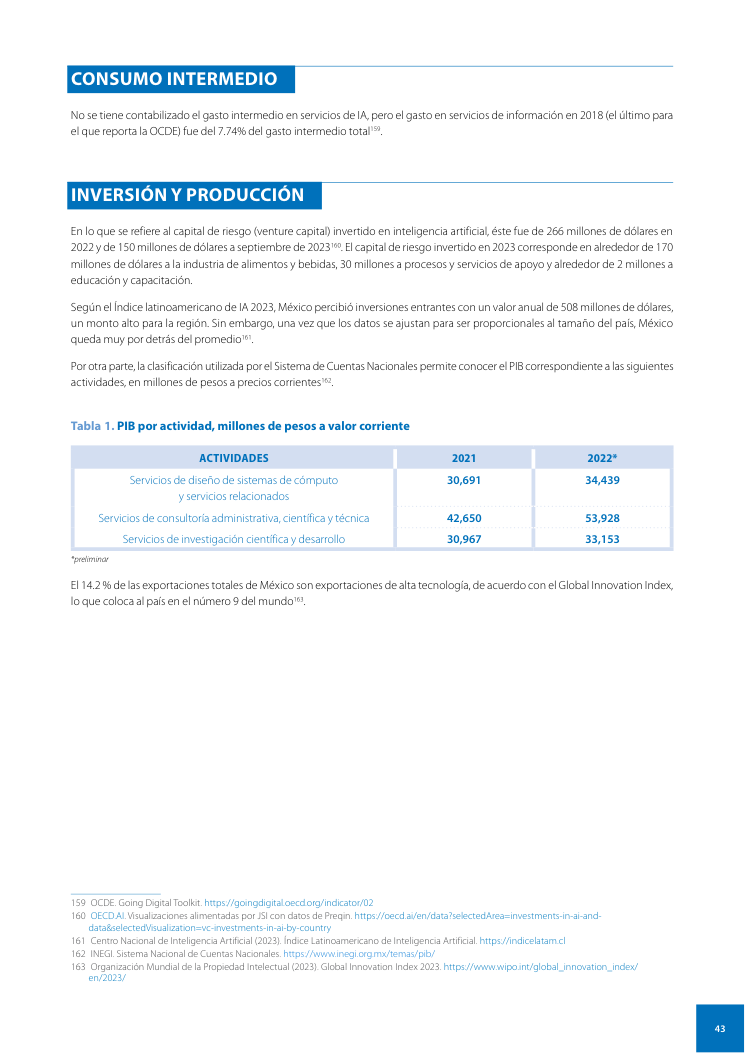

In [6]:
compare("unesco_ram_mexico.pdf", 45)

### INAI, página 35

C:\Projects\Maestria\PLN\RAG\.venv\Lib\site-packages\torch\nn\modules\conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\Convolution.cpp:1136.)
  return F.conv2d(


PRINCIPIO,FUNDAMENTOLEGAL,DEFINICIÓN,RECOMENDACIONES
Principio deconsentimiento,"• Artículos 6, ydel 8 al 10 dela LFPDPPP; 9,fracción II, y del11 al 21 de suReglamento.• Artículos 16,20 al 22 de laLGPDPPSO; 7,fracción IV, del12 al 20 y 54 delos LineamientosGenerales.","Como regla general, elresponsable deberá con-tar con el consentimientode la persona titular parael tratamiento de sus da-tos personales, entendidocomo la manifestación dela voluntad libre, específicae informada del titular delos datos mediante la cualse efectúa el tratamientode los mismos; salvo en loscasos de excepción pre-vistos en los artículos 10de la LFPDPPP, y 22 de laLGPDPPSO, según resulteaplicable. Cuando éste serequiera, la solicitud delconsentimiento deberá irsiempre ligada a las finali-dades concretas del trata-miento que se informen enel aviso de privacidad, esdecir, el consentimiento sedeberá solicitar para tratarlos datos personales parafinalidades específicas. Asi-mismo, el consentimientodebe ser informado, por loque, previo a su obtención,es necesario que la perso-na titular conozca el avisode privacidad. En el mismosentido, el consentimientodebe ser libre, es decir, nodebe mediar error, mala fe,violencia o dolo, que pue-dan afectar la manifesta-ción de voluntad de la per-sona titular. Ahora bien, elconsentimiento puede sertácito, expreso o expresoy por escrito, dependiendodel tipo de datos persona-les que se tratarán.","1. Recabar el consentimiento para eltratamiento de datos personales,cuando éste se requiera. Para ello,se deberá identificar si se actualizaalguna de las causales previstas enlos artículos 10 de la LFPDPPP o 22de la LGPDPPSO y, en caso de queno sea así, se deberá identificar eltipo de datos personales que sevan a tratar, para determinar si serequiere el consentimiento tácito,expreso o expreso y por escrito.2. Solicitar el consentimiento expresopara los datos personales financie-ros o patrimoniales.3. Solicitar el consentimiento expresoy por escrito para los datos perso-nales sensibles.4. Dar a conocer a la persona titular elaviso de privacidad previo a la ob-tención del consentimiento.5. Solicitar el consentimiento siempreligado a finalidades específicas e in-formadas en el aviso de privacidad.6. Solicitar el consentimiento previoa la obtención de los datos perso-nales o en el momento en que loindique la normatividad que resulteaplicable.7. Obtener el consentimiento paranuevas finalidades, cuando se pre-tenda tratar los datos personalespara fines distintos, que no seancompatibles o análogos a los es-tablecidos de origen en el aviso deprivacidad.8. Facilitar a la persona titular mediossencillos y gratuitos para que, en sucaso, pueda manifestar su consen-timiento o negativa al mismo."
Principio deconsentimiento,"• Artículos 6, ydel 8 al 10 dela LFPDPPP; 9,fracción II, y del11 al 21 de suReglamento.• Artículos 16,20 al 22 de laLGPDPPSO; 7,fracción IV, del12 al 20 y 54 delos LineamientosGenerales.","Como regla general, elresponsable deberá con-tar con el consentimientode la persona titular parael tratamiento de sus da-tos personales, entendidocomo la manifestación dela voluntad libre, específicae informada del titular delos datos mediante la cualse efectúa el tratamientode los mismos; salvo en loscasos de excepción pre-vistos en los artículos 10de la LFPDPPP, y 22 de laLGPDPPSO, según resulteaplicable. Cuando éste serequiera, la solicitud delconsentimiento deberá irsiempre ligada a las finali-dades concretas del trata-miento que se informen enel aviso de privacidad, esdecir, el consentimiento sedeberá solicitar para tratarlos datos personales parafinalidades específicas. Asi-mismo, el consentimientodebe ser informado, por loque, previo a su obtención,es necesario que la perso-na titular conozca el avisode privacidad. En el mismosentido, el consentimientodebe ser libre, es decir, nodebe mediar error, mala fe,violencia o dolo, que pue-dan afectar la manifesta-ción de voluntad de la per-sona titular. Ahora bien, elconsentimiento puede 
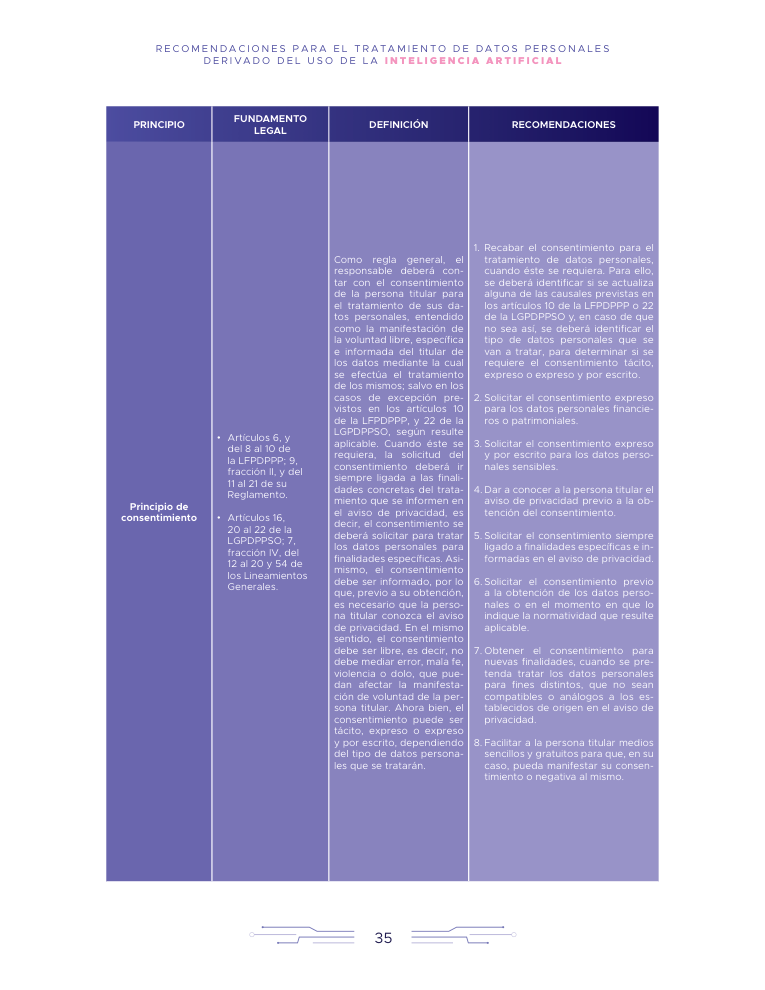

In [7]:
compare("inai_recomendaciones_ia.pdf", 35)

### Iniciativa, página 28

[WARNING] 2026-11-12 22:13:45,122 [RapidOCR] main.py:164: The text detection result is empty


RapidOCR returned empty result!



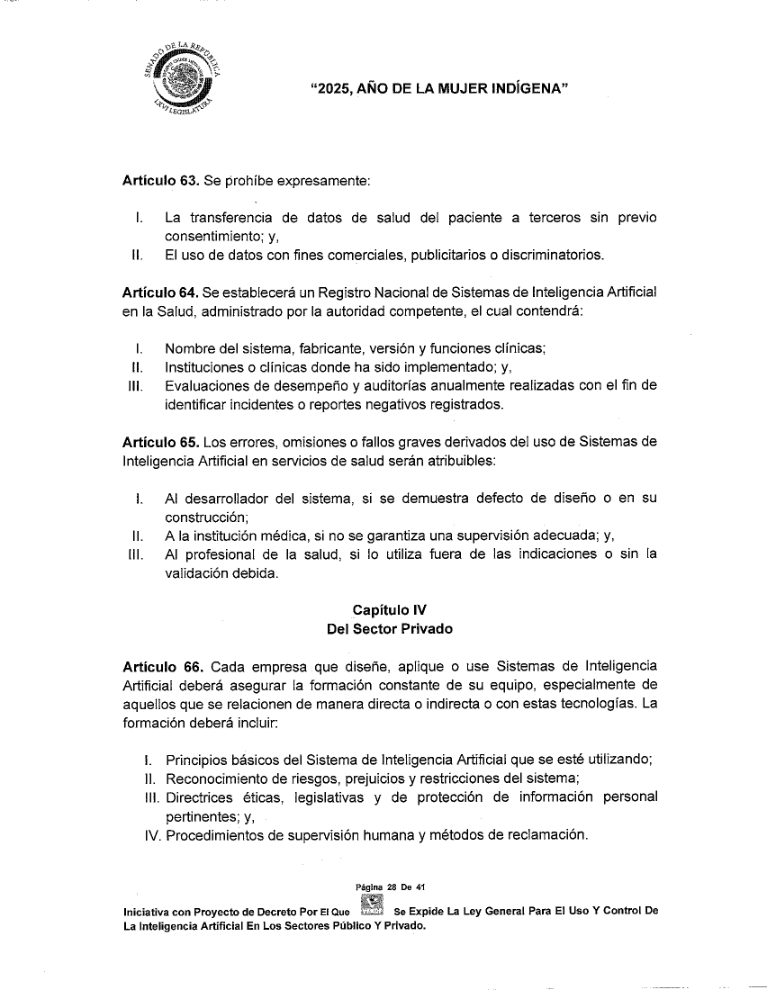

In [8]:
compare("iniciativa_ley_ia_senado.pdf", 28)

## Docling sin OCR

Se repite la página 28 de la iniciativa con el OCR de Docling desactivado (`do_ocr=False`). Así, Docling usa el texto que ya trae el PDF, igual que PyMuPDF y pdfplumber, y conserva su modelo de diseño y TableFormer.

Se compara contra pdfplumber y contra Docling con su configuración por defecto.

In [9]:
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.document_converter import PdfFormatOption

start = time.perf_counter()
converter_no_ocr = DocumentConverter(
    format_options={InputFormat.PDF: PdfFormatOption(pipeline_options=PdfPipelineOptions(do_ocr=False))}
)
converter_no_ocr.initialize_pipeline(InputFormat.PDF)
print(f"Carga de modelos: {time.perf_counter() - start:.2f} s")


def parse_docling_no_ocr(pdf_path, page_number):
    return parse_docling(pdf_path, page_number, converter_no_ocr)

Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

Loading weights:  47%|████▋     | 364/770 [00:00<00:00, 3613.06it/s]

Loading weights: 100%|██████████| 770/770 [00:00<00:00, 5628.03it/s]

Carga de modelos: 1.17 s


Principio deconsentimiento,"• Artículos 6, ydel 8 al 10 dela LFPDPPP; 9,fracción II, y del11 al 21 de suReglamento.• Artículos 16,20 al 22 de laLGPDPPSO; 7,fracción IV, del12 al 20 y 54 delos LineamientosGenerales.","Como regla general, elresponsable deberá con-tar con el consentimientode la persona titular parael tratamiento de sus da-tos personales, entendidocomo la manifestación dela voluntad libre, específicae informada del titular delos datos mediante la cualse efectúa el tratamientode los mismos; salvo en loscasos de excepción pre-vistos en los artículos 10de la LFPDPPP, y 22 de laLGPDPPSO, según resulteaplicable. Cuando éste serequiera, la solicitud delconsentimiento deberá irsiempre ligada a las finali-dades concretas del trata-miento que se informen enel aviso de privacidad, esdecir, el consentimiento sedeberá solicitar para tratarlos datos personales parafinalidades específicas. Asi-mismo, el consentimientodebe ser informado, por loque, previo a su obtención,es necesario que la perso-na titular conozca el avisode privacidad. En el mismosentido, el consentimientodebe ser libre, es decir, nodebe mediar error, mala fe,violencia o dolo, que pue-dan afectar la manifesta-ción de voluntad de la per-sona titular. Ahora bien, elconsentimiento puede sertácito, expreso o expresoy por escrito, dependiendodel tipo de datos persona-les que se tratarán.","1. Recabar el consentimiento para eltratamiento de datos personales,cuando éste se requiera. Para ello,se deberá identificar si se actualizaalguna de las causales previstas enlos artículos 10 de la LFPDPPP o 22de la LGPDPPSO y, en caso de queno sea así, se deberá identificar eltipo de datos personales que sevan a tratar, para determinar si serequiere el consentimiento tácito,expreso o expreso y por escrito.2. Solicitar el consentimiento expresopara los datos personales financie-ros o patrimoniales.3. Solicitar el consentimiento expresoy por escrito para los datos perso-nales sensibles.4. Dar a conocer a la persona titular elaviso de privacidad previo a la ob-tención del consentimiento.5. Solicitar el consentimiento siempreligado a finalidades específicas e in-formadas en el aviso de privacidad.6. Solicitar el consentimiento previoa la obtención de los datos perso-nales o en el momento en que loindique la normatividad que resulteaplicable.7. Obtener el consentimiento paranuevas finalidades, cuando se pre-tenda tratar los datos personalespara fines distintos, que no seancompatibles o análogos a los es-tablecidos de origen en el aviso deprivacidad.8. Facilitar a la persona titular mediossencillos y gratuitos para que, en sucaso, pueda manifestar su consen-timiento o negativa al mismo."

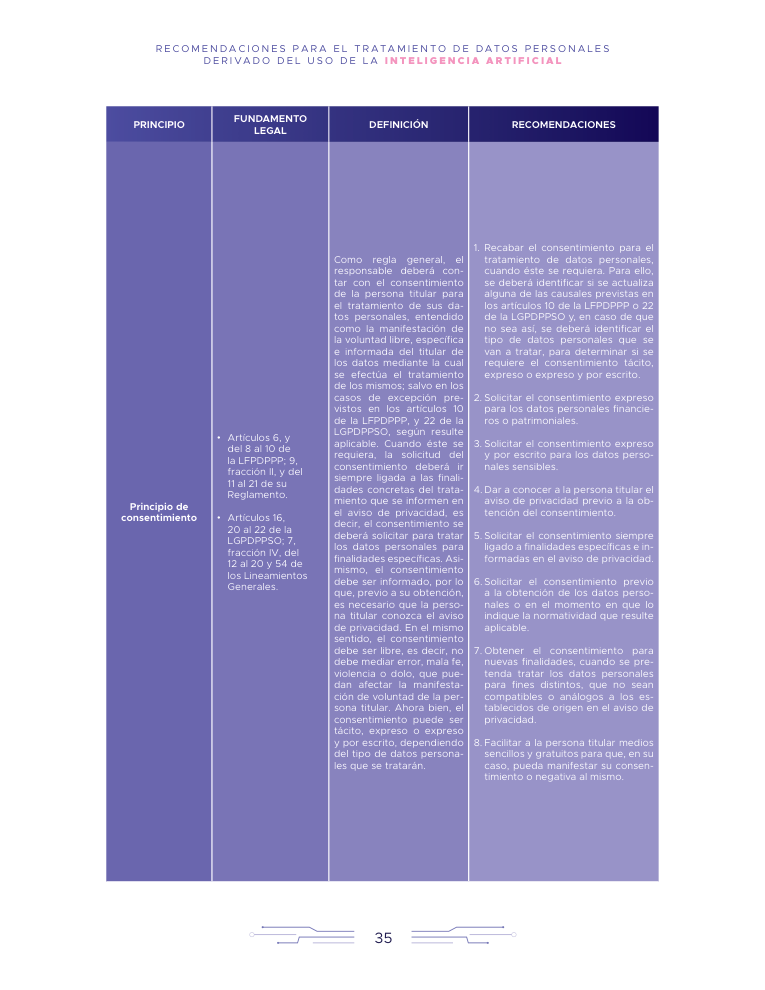

In [10]:
compare(
    "inai_recomendaciones_ia.pdf",
    35,
    parsers={"pdfplumber": parse_pdfplumber, "Docling": parse_docling, "Docling sin OCR": parse_docling_no_ocr},
)

## Decisión: Docling sin OCR

Se elige Docling con el OCR desactivado (`do_ocr=False`).

- **UNESCO, p. 45.** Fue el único que dejó cada actividad de la tabla en la misma fila que sus cifras y que separó el marcador de nota del año (`2023 160` en lugar de `2023160`). También marca los títulos y quita el número de página.
- **Iniciativa, p. 28.** Sin OCR conserva todo el texto. Con OCR, Docling volvió ilegibles las fracciones III y IV del artículo 66.
- **INAI, p. 35.** No detecta la tabla, con o sin OCR, pero el texto de cada celda queda completo y en orden.
- **Descartados.** pdfplumber intercala las columnas de la tabla del INAI línea por línea, así que esas oraciones no se pueden recuperar. PyMuPDF extrae bien el texto, pero habría que escribir reglas para unir palabras con guion, quitar encabezados y pies, y separar las notas al pie.

**Pendiente con cualquier parser:** los números romanos mal leídos en la iniciativa (`11.` por `II.`), porque el error viene del texto del PDF, y el encabezado «2025, AÑO DE LA MUJER INDÍGENA», que se repite en cada página.

**Costo:** entre 0.7 y 2 s por página en CPU y unos 500 MB de modelos, frente a menos de 0.3 s por página de PyMuPDF.

## Decisión: unidad del resultado

Se guarda el JSON completo de Docling por documento y, a partir de él, un registro por elemento.

- **JSON de Docling** (`data/docling/<doc_id>.json`): conserva todo lo que detectó Docling, incluida la estructura de las tablas. Las decisiones siguientes se aplican sobre este archivo sin volver a correr los modelos.
- **Registro por elemento**: documento, página del PDF, página impresa, etiqueta de Docling (párrafo, título, elemento de lista, nota al pie, tabla...), capa (cuerpo o encabezado y pie de página), título de sección vigente y texto.

La página del PDF es la clave para el ground truth porque no es ambigua. La página impresa sale del desplazamiento del manifiesto (en UNESCO es la del PDF menos 2) y sirve para citar.

## Conversión del corpus

Cada PDF se convierte una sola vez con la configuración elegida.

In [11]:
import json

from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.document_converter import DocumentConverter, PdfFormatOption

DATA = Path("../data")
DOCLING_DIR = DATA / "docling"
DOCLING_DIR.mkdir(exist_ok=True)
MANIFEST = json.loads((DATA / "manifest.json").read_text(encoding="utf-8"))["documents"]

corpus_converter = DocumentConverter(
    format_options={InputFormat.PDF: PdfFormatOption(pipeline_options=PdfPipelineOptions(do_ocr=False))}
)

for entry in MANIFEST:
    output = DOCLING_DIR / f"{entry['doc_id']}.json"
    if output.exists():
        print(f"{entry['doc_id']}: ya convertido")
        continue
    start = time.perf_counter()
    document = corpus_converter.convert(RAW / entry["file"]).document
    document.save_as_json(output)
    seconds = time.perf_counter() - start
    print(f"{entry['doc_id']}: {len(document.pages)} páginas en {seconds:.0f} s ({seconds / len(document.pages):.1f} s por página)")

lfpdppp: ya convertido
lgpdppso: ya convertido
reglamento_lfpdppp: ya convertido
inai_recomendaciones_ia: ya convertido
unesco_ram_mexico: ya convertido
principios_chapultepec: ya convertido
iniciativa_ley_ia_senado: ya convertido


## Elementos

Se recorren todos los elementos de cada documento, incluidos los encabezados y pies de página (capa `furniture`), para decidir después qué hacer con ellos. Por ahora:

- En los elementos de lista, Docling guarda el numeral (`XII.`, `11.`) aparte del texto. Se vuelve a unir para no perder las fracciones de los artículos.
- Las tablas se guardan primero como Markdown; su formato final se aplica en «Decisión: formato de las tablas».
- Las imágenes se guardan sin texto, para saber dónde están.
- Si un elemento cruza de una página a otra, `page` es la primera y `page_end` la última.
- `y` es la altura del centro del elemento en su primera página: 0 es el borde superior y 1 el inferior.
- `ref` es la referencia del elemento en el JSON de Docling (por ejemplo, `#/tables/3`).
- El título de sección vigente se asigna después de quitar los encabezados y pies repetidos, porque Docling marca algunos de ellos como títulos.

Los documentos de Docling quedan cargados en `DOCUMENTS` para los pasos siguientes.

In [12]:
import pandas as pd
from docling_core.types.doc import ContentLayer, DoclingDocument

DOCUMENTS = {
    entry["doc_id"]: DoclingDocument.load_from_json(DOCLING_DIR / f"{entry['doc_id']}.json") for entry in MANIFEST
}


def element_text(item, document):
    label = str(item.label)
    if label == "table":
        return item.export_to_markdown(doc=document)
    text = getattr(item, "text", "") or ""
    marker = getattr(item, "marker", "") or ""
    return f"{marker} {text}" if marker else text


def vertical_position(item, document):
    """Height of the element's center on its first page: 0 is the top edge and 1 the bottom edge."""
    prov = item.prov[0]
    page_height = document.pages[prov.page_no].size.height
    box = prov.bbox.to_top_left_origin(page_height=page_height)
    return round((box.t + box.b) / 2 / page_height, 3)


def build_elements(entry):
    document = DOCUMENTS[entry["doc_id"]]
    rows = []
    for item, _ in document.iterate_items(included_content_layers=set(ContentLayer)):
        pages = sorted({prov.page_no for prov in item.prov})
        rows.append({
            "doc_id": entry["doc_id"],
            "page": pages[0] if pages else None,
            "page_end": pages[-1] if pages else None,
            "printed_page": pages[0] + entry["printed_page_offset"] if pages else None,
            "y": vertical_position(item, document) if item.prov else None,
            "label": str(item.label),
            "layer": str(item.content_layer.value),
            "text": element_text(item, document),
            "ref": item.self_ref,
        })
    return rows


elements = pd.DataFrame([row for entry in MANIFEST for row in build_elements(entry)])
print(f"{len(elements)} elementos en {elements['doc_id'].nunique()} documentos")
print(f"Elementos que cruzan de página: {(elements['page'] != elements['page_end']).sum()}")
elements.pivot_table(index="doc_id", columns="label", values="text", aggfunc="count", fill_value=0)

4510 elementos en 7 documentos
Elementos que cruzan de página: 10


label,caption,document_index,footnote,list_item,page_footer,page_header,picture,section_header,table,text
doc_id,,,,,,,,,,
inai_recomendaciones_ia,0,1,74,97,39,15,27,71,18,201
iniciativa_ley_ia_senado,1,0,0,288,87,0,83,89,0,186
lfpdppp,0,0,0,139,24,0,24,46,0,214
lgpdppso,0,0,1,342,37,0,37,104,0,395
principios_chapultepec,0,0,0,31,0,0,10,11,0,2
reglamento_lfpdppp,0,0,0,200,36,7,36,200,0,354
unesco_ram_mexico,19,3,198,202,69,0,30,56,5,401


## Decisión: texto que Docling omitió

Cada línea de texto del PDF, leída con PyMuPDF, se compara con las cajas de los elementos de Docling. Una línea está cubierta si su centro cae dentro de la caja de algún elemento, con un margen de 3 puntos. En todo el corpus solo 13 líneas quedan sin cubrir: las notas 57, 75 a 77, 86 y 87 del INAI, en las páginas 20, 26 y 31. En las tres páginas hay una imagen grande justo encima de las notas.

Esas líneas se recuperan del texto del PDF:

- Las líneas seguidas de una misma página forman un elemento. Una línea que empieza con un número inicia uno nuevo.
- Un elemento recuperado que empieza con un número se etiqueta como nota al pie; si no, como párrafo.
- Se insertan al final de su página, en el orden de lectura. La columna `source` dice `pymupdf` en lugar de `docling`.

Se descartaron aceptar la pérdida, porque la nota 76 trae una definición de cómputo en la nube, y escribir las notas a mano, porque no serviría para otros documentos.

La comprobación es por posición: confirma que cada línea cae dentro de algún elemento, no que el texto del elemento tenga todas sus palabras. Las líneas dentro de imágenes (gráficas, infografías, el sello) cuentan como cubiertas; su tratamiento se decide con las figuras. Con más documentos, esta misma comprobación avisa dónde el parser omitió texto sin revisar cada página.

In [13]:
import re
from collections import defaultdict

COVER_MARGIN = 3  # points added around each Docling box
STARTS_WITH_NUMBER = re.compile(r"\d{1,3}\s")


def docling_boxes(document):
    """Box of every Docling element, per page, in top-left coordinates and widened by the margin."""
    boxes = defaultdict(list)
    for item, _ in document.iterate_items(included_content_layers=set(ContentLayer)):
        for prov in item.prov:
            box = prov.bbox.to_top_left_origin(page_height=document.pages[prov.page_no].size.height)
            boxes[prov.page_no].append(
                (box.l - COVER_MARGIN, box.t - COVER_MARGIN, box.r + COVER_MARGIN, box.b + COVER_MARGIN)
            )
    return boxes


def uncovered_lines(entry):
    """PDF text lines, read with PyMuPDF, whose center falls inside no Docling element."""
    boxes = docling_boxes(DOCUMENTS[entry["doc_id"]])
    lines = []
    with fitz.open(RAW / entry["file"]) as pdf:
        for page in pdf:
            for block in page.get_text("dict", sort=True)["blocks"]:
                for line in block.get("lines", []):
                    text = re.sub(r"\s+", " ", "".join(span["text"] for span in line["spans"])).strip()
                    x0, y0, x1, y1 = line["bbox"]
                    center_x, center_y = (x0 + x1) / 2, (y0 + y1) / 2
                    covered = any(
                        left <= center_x <= right and top <= center_y <= bottom
                        for left, top, right, bottom in boxes[page.number + 1]
                    )
                    if text and not covered:
                        lines.append({"page": page.number + 1, "y": round(center_y / page.rect.height, 3), "text": text})
    return lines


def group_lines(entry, lines):
    """Join consecutive lines of a page into elements; a line that starts with a number starts a new one."""
    rows = []
    for line in lines:
        previous = rows[-1] if rows else None
        if previous and previous["page"] == line["page"] and not STARTS_WITH_NUMBER.match(line["text"]):
            if previous["text"].endswith("-") and line["text"][:1].islower():
                previous["text"] = previous["text"][:-1] + line["text"]
            else:
                previous["text"] += " " + line["text"]
            continue
        rows.append({
            "doc_id": entry["doc_id"],
            "page": line["page"],
            "page_end": line["page"],
            "printed_page": line["page"] + entry["printed_page_offset"],
            "y": line["y"],
            "label": None,
            "layer": "body",
            "text": line["text"],
            "source": "pymupdf",
        })
    for row in rows:
        row["label"] = "footnote" if STARTS_WITH_NUMBER.match(row["text"]) else "text"
    return rows


def reading_positions(elements, recovered):
    """Position of each recovered element: after the last element of its document on the same or an earlier page."""
    positions = []
    for number, row in enumerate(recovered.itertuples(), start=1):
        same_document = elements[elements["doc_id"] == row.doc_id]
        earlier = same_document[same_document["page"] <= row.page]
        anchor = earlier.index.max() if len(earlier) else same_document.index.min() - 1
        positions.append(anchor + number / 1_000_000)
    return positions


uncovered = {entry["doc_id"]: uncovered_lines(entry) for entry in MANIFEST}
recovered = pd.DataFrame([row for entry in MANIFEST for row in group_lines(entry, uncovered[entry["doc_id"]])])
print(f"Líneas del PDF sin elemento de Docling: {sum(len(lines) for lines in uncovered.values())}")
print(f"Elementos recuperados: {len(recovered)}")

elements["source"] = "docling"
if len(recovered):
    recovered["position"] = reading_positions(elements, recovered)
    elements = (
        pd.concat([elements.assign(position=elements.index.astype(float)), recovered])
        .sort_values("position", kind="stable")
        .drop(columns="position")
        .reset_index(drop=True)
    )
    with pd.option_context("display.max_colwidth", 120):
        display(recovered[["doc_id", "page", "y", "label", "text"]])

Líneas del PDF sin elemento de Docling: 13
Elementos recuperados: 6


,doc_id,page,y,label,text
0,inai_recomendaciones_ia,20,0.877,footnote,"57 Disponible en: https://observatorio.tec.mx/edu-news/10-programas-adaptivos-para-apoyar-la-enseanza-personalizada,..."
1,inai_recomendaciones_ia,26,0.785,footnote,"75 Disponible en: https://www.technologyreview.es/s/10025/tr10-inteligencia-artificial-en-la-nube, [consulta: 7 de m..."
2,inai_recomendaciones_ia,26,0.813,footnote,76 Computo en la nube: modelo de abastecimiento y entrega externa de servicios de acceso a recursos informáticos y s...
3,inai_recomendaciones_ia,26,0.877,footnote,77 Disponible en: https://blog.powerdata.es/el-valor-de-la-gestion-de-datos/como-la-inteligencia-artificial-mejora-c...
4,inai_recomendaciones_ia,31,0.873,footnote,"86 Disponible en: https://www.redalyc.org/journal/2815/281561305009/html/, [consulta: 7 de mayo de 2022]."
5,inai_recomendaciones_ia,31,0.889,footnote,"87 Disponible en: https://www.redalyc.org/journal/2815/281561305009/html/, [consulta: 7 de mayo de 2022]."


## Decisión: formato de las tablas

Docling encontró 23 tablas: 18 en el INAI y 5 en UNESCO. Una de UNESCO (p. 27) es una gráfica y quedó vacía. Su Markdown tenía tres problemas:

- **Relleno.** Más de la mitad de los caracteres eran espacios y guiones para alinear las columnas.
- **Columnas sin información.** En las listas de verificación del INAI (pp. 42 a 46), las columnas «Si», «No» y «No aplica» solo tienen la «o» de una casilla vacía.
- **Cabecera perdida al dividir.** Casi todas las tablas son más largas que un fragmento, y en Markdown las filas que quedan en otro fragmento pierden el nombre de las columnas.

Cada tabla se escribe con una línea por fila:

- Si Docling detectó la cabecera, cada valor lleva el nombre de su columna: `ACTIVIDADES: Servicios de diseño…; 2021: 30,691; 2022*: 34,439`. Si no, las celdas se unen con ` | `.
- Se quitan las columnas que solo tienen casillas vacías.
- Se unen las palabras partidas con guion dentro de las celdas («da- tos»). Docling las une en los párrafos, pero no en las tablas.

Se descartaron el Markdown de Docling y un Markdown compacto sin relleno, porque en los dos las filas pierden la cabecera cuando la tabla se divide.

**Limitaciones:** 8 tablas no tienen cabecera detectada. En la de la p. 12 del INAI, los títulos de columna («AUTOR», «AÑO», «DEFINICIÓN») quedaron como párrafos aparte. En la tabla de la p. 38, Docling tomó una fila de contenido como cabecera.

In [14]:
SPLIT_WORD = re.compile(r"(\w)- (?=[a-záéíóúñ])")
CHECKBOX_VALUES = {"", "o"}


def clean_cell(value):
    """Collapse whitespace and join words split by a hyphen at a line end."""
    return SPLIT_WORD.sub(r"\1", re.sub(r"\s+", " ", str(value))).strip()


def table_rows(table, document):
    """One line per row. With a detected header, each value carries its column name.
    Columns that only hold empty checkbox marks are dropped."""
    frame = table.export_to_dataframe(doc=document)
    if frame.empty:
        return ""
    header = [clean_cell(name) for name in frame.columns]
    rows = [[clean_cell(value) for value in row] for row in frame.values.tolist()]
    has_header = not all(name.isdigit() for name in header)
    keep = [k for k in range(len(header)) if not all(row[k].lower() in CHECKBOX_VALUES for row in rows)]
    lines = []
    for row in rows:
        if has_header:
            lines.append("; ".join(f"{header[k]}: {row[k]}" for k in keep if row[k]))
        else:
            lines.append(" | ".join(row[k] for k in keep if row[k]))
    return "\n".join(lines)


is_table = elements["label"] == "table"
markdown_chars = elements.loc[is_table, "text"].str.len().sum()
split_words = elements.loc[is_table, "text"].map(lambda text: len(SPLIT_WORD.findall(text))).sum()
for index in elements.index[is_table]:
    document = DOCUMENTS[elements.at[index, "doc_id"]]
    table = document.tables[int(elements.at[index, "ref"].rsplit("/", 1)[1])]
    elements.at[index, "text"] = table_rows(table, document)

row_chars = elements.loc[is_table, "text"].str.len().sum()
rows = elements.loc[is_table, "text"].map(lambda text: len(text.splitlines())).sum()
print(f"Tablas: {is_table.sum()}, con {rows} filas")
print(f"Caracteres: {markdown_chars:,} en Markdown, {row_chars:,} con una línea por fila")
print(f"Palabras partidas con guion unidas: {split_words}")
for doc_id, page in [("unesco_ram_mexico", 45), ("inai_recomendaciones_ia", 42)]:
    text = elements.loc[is_table & (elements["doc_id"] == doc_id) & (elements["page"] == page), "text"].iloc[0]
    print(f"\n{doc_id}, p. {page}:")
    print("\n".join(text.splitlines()[:3]))

Tablas: 23, con 148 filas
Caracteres: 69,003 en Markdown, 30,987 con una línea por fila
Palabras partidas con guion unidas: 84

unesco_ram_mexico, p. 45:
ACTIVIDADES: Servicios de diseño de sistemas de cómputo y servicios relacionados; 2021: 30,691; 2022*: 34,439
ACTIVIDADES: Servicios de consultoría administrativa, científica y técnica; 2021: 42,650; 2022*: 53,928
ACTIVIDADES: Servicios de investigación científica y desarrollo; 2021: 30,967; 2022*: 33,153

inai_recomendaciones_ia, p. 42:
Pregunta: ¿Conoce la normativa que regula el tratamiento de datos personales del producto o servicio de IA que desarrolla o utiliza?
Pregunta: En el caso del sector público: ¿Cuenta con facultades o atribuciones para realizar el tratamiento de datos personales del producto o servicio de IA que desarrolla o utiliza?
Pregunta: ¿Ha revisado si existe normatividad que sea vinculante de manera directa o indirecta con la protección o el tratamiento de datos personales del producto o servicio de IA que desar

## Decisión: encabezados y pies de página repetidos

Docling solo marcó como encabezado o pie (capa `furniture`) una parte de lo que se repite en cada página. Quedaron en el cuerpo:

| Documento | Texto repetido que quedó en el cuerpo | Páginas |
|---|---|---|
| LFPDPPP, LGPDPPSO, Reglamento | «CÁMARA DE DIPUTADOS… Secretaría General…», «Última Reforma DOF…» y el título de la ley, marcado como título de sección | Todas o casi todas |
| INAI | El encabezado con letras espaciadas, marcado como título de sección | 29 de 48 |
| Iniciativa | «2025, AÑO DE LA MUJER INDÍGENA», marcado como título de sección, y «Página # De #» | 40 y 13 de 42 |

Como varios están marcados como títulos, el título de sección vigente de la mayoría de los elementos era el de la ley o el lema del año. Además, el texto repetido inflaría términos como «protección de datos personales» en la búsqueda por palabras clave.

Se quitan con tres reglas, en este orden:

1. **Capa `furniture`.** Todo lo que Docling marcó como encabezado o pie de página.
2. **Repetición.** El texto se normaliza (sin dígitos ni espacios y en minúsculas), así «1 de 24» y «2 de 24», o las letras espaciadas, cuentan como el mismo texto. Se quita todo elemento cuyo texto normalizado aparece en al menos el 30 % de las páginas del documento (mínimo 3), contando las dos capas.
3. **Similitud.** En las franjas superior e inferior de la página (12 % de su altura), se quita un elemento del cuerpo si su texto normalizado está contenido en un texto repetido o se le parece al menos en un 85 %. Así se quitan los encabezados que Docling partió en dos piezas en algunas páginas y el lema mal leído «2_025, AÑO…».

No se borra nada: la columna `removed` guarda la regla que quitó cada elemento, para poder revisarlo.

**Umbral.** Con 30 % y sin la regla 3 quedaban las piezas del encabezado en 9 páginas del Reglamento. Bajar a 25 % las captura solo porque son justo 9 de 36 páginas, y con 20 % ya se quita texto de la mitad de la página en el INAI.

**Con un parser de reglas sería peor.** PyMuPDF no marca nada como encabezado o pie, y la regla de repetición sola borraría 419 numerales de fracción (`I.`, `II.`…), porque los deja en una línea propia. Docling une el numeral al elemento.

**Limitaciones conocidas:**
- El título de cada ley también aparece en su portada, así que ahí se quita. El título queda en el manifiesto.
- En la iniciativa, el ruido de OCR del sello cambia el pie de página en cada hoja. Donde Docling no lo marcó como pie (páginas 3, 15, 19, 25 y 36), no se parece lo suficiente a ningún texto repetido y se queda.
- Docling marcó como pie de página dos textos con contenido en UNESCO: la nota 6 (p. 16) y la fuente de la figura de la p. 50. La regla 1 los quita.
- Las imágenes (logos, sello) no tienen texto, así que estas reglas no las tocan. Se deciden más adelante.

In [15]:
import re
from difflib import SequenceMatcher

REPEAT_SHARE = 0.30  # share of the document's pages
MIN_REPEAT_PAGES = 3
STRIP = 0.12  # top and bottom strips, as a share of the page height
MIN_SIMILARITY = 0.85


def normalize(text):
    """Remove digits and whitespace and lowercase, so page numbers and letter spacing don't hide a repetition."""
    return re.sub(r"[\d\s]+", "", text).lower()


def removal_reasons(doc_rows):
    """For each element of one document, the rule that removes it, or None if it stays."""
    keys = doc_rows["text"].map(normalize)
    n_pages = len(DOCUMENTS[doc_rows["doc_id"].iloc[0]].pages)
    pages_per_key = doc_rows.groupby(keys)["page"].nunique()
    repeated = set(pages_per_key[pages_per_key >= max(MIN_REPEAT_PAGES, REPEAT_SHARE * n_pages)].index) - {""}

    def similar(key):
        return any(key in text or SequenceMatcher(None, key, text).ratio() >= MIN_SIMILARITY for text in repeated)

    reasons = []
    for (_, row), key in zip(doc_rows.iterrows(), keys):
        in_strip = row["y"] < STRIP or row["y"] > 1 - STRIP
        if row["layer"] == "furniture":
            reasons.append("furniture")
        elif key in repeated:
            reasons.append("repetición")
        elif key and in_strip and similar(key):
            reasons.append("similitud")
        else:
            reasons.append(None)
    return reasons


elements["removed"] = None
for doc_id, doc_rows in elements.groupby("doc_id"):
    elements.loc[doc_rows.index, "removed"] = removal_reasons(doc_rows)

kept = elements["removed"].isna()
print(f"Se quitan {(~kept).sum()} de {len(elements)} elementos; quedan {kept.sum()}")
(
    elements.assign(removed=elements["removed"].fillna("se queda"))
    .pivot_table(index="doc_id", columns="removed", values="text", aggfunc="count", fill_value=0)
    .reindex(index=[entry["doc_id"] for entry in MANIFEST], columns=["furniture", "repetición", "similitud", "se queda"], fill_value=0)
)

Se quitan 697 de 4516 elementos; quedan 3819


removed,furniture,repetición,similitud,se queda
doc_id,,,,
lfpdppp,24,73,2,348
lgpdppso,37,113,0,766
reglamento_lfpdppp,43,93,18,679
inai_recomendaciones_ia,54,29,0,466
unesco_ram_mexico,69,0,0,914
principios_chapultepec,0,0,0,54
iniciativa_ley_ia_senado,87,54,1,592


### Registro de lo que se quita

Una fila por texto distinto (normalizado), con la regla que lo quitó, en cuántas páginas aparece y un ejemplo.

In [16]:
removed_log = (
    elements[~kept]
    .assign(key=lambda frame: frame["text"].map(normalize))
    .groupby(["doc_id", "removed", "key"], sort=False)
    .agg(pages=("page", "nunique"), example=("text", "first"))
    .reset_index()
    .drop(columns="key")
    .assign(doc_id=lambda frame: pd.Categorical(frame["doc_id"], [entry["doc_id"] for entry in MANIFEST]))
    .sort_values(["doc_id", "removed", "pages"], ascending=[True, True, False], ignore_index=True)
)
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 100):
    display(removed_log)

,doc_id,removed,pages,example
0,lfpdppp,furniture,24,1 de 24
1,lfpdppp,repetición,24,LEY FEDERAL DE PROTECCIÓN DE DATOS PERSONALES EN POSESIÓN DE LOS PARTICULARES
2,lfpdppp,repetición,24,Última Reforma DOF 14-11-2025
3,lfpdppp,repetición,23,CÁMARA DE DIPUTADOS DEL H. CONGRESO DE LA UNIÓN Secretaría General Secretaría de Servicios Parla...
4,lfpdppp,similitud,1,CÁMARA DE DIPUTADOS DEL H. CONGRESO DE LA UNIÓN Secretaría General
5,lfpdppp,similitud,1,Secretaría de Servicios Parlamentarios
6,lgpdppso,furniture,37,1 de 37
7,lgpdppso,repetición,37,LEY GENERAL DE PROTECCIÓN DE DATOS PERSONALES EN POSESIÓN DE SUJETOS OBLIGADOS
8,lgpdppso,repetición,37,CÁMARA DE DIPUTADOS DEL H. CONGRESO DE LA UNIÓN Secretaría General Secretaría de Servicios Parla...
9,lgpdppso,repetición,37,Última Reforma DOF 14-11-2025


### Título de sección vigente

Con los elementos que quedan, el título de sección vigente de cada uno es el último `section_header` o `title` del cuerpo que lo precede. Docling no anida los títulos, así que no hay jerarquía.

La tabla compara el título más frecuente de cada documento antes y después de quitar los encabezados y pies.

In [17]:
HEADING_LABELS = {"section_header", "title"}


def assign_headings(frame):
    """Last section_header or title of the body before each element, within its document."""
    is_heading = frame["label"].isin(HEADING_LABELS) & (frame["layer"] == "body")
    return frame["text"].where(is_heading).groupby(frame["doc_id"]).ffill()


def top_heading(headings):
    counts = headings.value_counts()
    return f"{counts.index[0][:70]} ({counts.iloc[0]} elementos)" if len(counts) else "—"


elements["heading"] = assign_headings(elements[kept])
headings_before = assign_headings(elements)
headings_table = pd.DataFrame({
    "antes": headings_before.groupby(elements["doc_id"]).agg(top_heading),
    "después": elements.loc[kept, "heading"].groupby(elements.loc[kept, "doc_id"]).agg(top_heading),
}).reindex([entry["doc_id"] for entry in MANIFEST])
with pd.option_context("display.max_colwidth", 100):
    display(headings_table)

,antes,después
doc_id,,
lfpdppp,LEY FEDERAL DE PROTECCIÓN DE DATOS PERSONALES EN POSESIÓN DE LOS PARTI (325 elementos),Transitorios (62 elementos)
lgpdppso,LEY GENERAL DE PROTECCIÓN DE DATOS PERSONALES EN POSESIÓN DE SUJETOS O (593 elementos),Del Recurso de Revisión (117 elementos)
reglamento_lfpdppp,REGLAMENTO DE LA LEY FEDERAL DE PROTECCIÓN DE DATOS PERSONALES EN POSE (197 elementos),Definiciones (23 elementos)
inai_recomendaciones_ia,RECOMENDAC I ONES PARA EL TRATAM I ENTO DE DATOS PERSONALES DER I VADO (244 elementos),¿CUÁL ES LA RELACIÓN ENTRE LA INTELIGENCIA ARTIFICIAL Y LA PROTECCIÓN (96 elementos)
unesco_ram_mexico,ANEXO 2 (184 elementos),ANEXO 2 (176 elementos)
principios_chapultepec,2.- Toda decisión apoyada por inteligencia artificial debe tener respo (17 elementos),2.- Toda decisión apoyada por inteligencia artificial debe tener respo (17 elementos)
iniciativa_ley_ia_senado,"""2025, AÑO DE LA MUJER INDÍGENA"" (385 elementos)","Artículo 8. Para los efectos de la presente ley, se entiende por: (70 elementos)"


## Decisión: índices

Docling detectó los cuatro índices del corpus y los etiquetó como `document_index`: el del INAI (p. 3) y los de UNESCO (pp. 5 a 7: tabla de contenido y lista de figuras y tablas). Sus elementos ya no tienen texto en los registros, porque `element_text` solo exporta como Markdown los elementos etiquetados como tabla.

Aun así se quitan de forma explícita, con `removed = "índice"`, para que no dependa de ese detalle del código. Si más adelante se exportara su texto, cada título de sección volvería a aparecer y la búsqueda por palabras clave pondría los índices arriba en muchas consultas, aunque no contienen respuestas.

Los títulos de los índices («ÍNDICE», «Tabla de Contenido», «Lista de figuras y tablas», «FIGURAS») se quedan, pero no tienen texto debajo.

In [18]:
is_index = elements["label"] == "document_index"
elements.loc[is_index, "removed"] = "índice"
elements.loc[is_index, "heading"] = None
kept = elements["removed"].isna()
print(f"Índices quitados: {is_index.sum()}")
elements.loc[is_index, ["doc_id", "page", "label", "removed"]]

Índices quitados: 4


,doc_id,page,label,removed
2207,inai_recomendaciones_ia,3,document_index,índice
2768,unesco_ram_mexico,5,document_index,índice
2770,unesco_ram_mexico,6,document_index,índice
2773,unesco_ram_mexico,7,document_index,índice


## Decisión: notas al pie

Solo el INAI (90 notas) y UNESCO (199) tienen notas al pie. Docling pone cada nota al final de su página, dentro del orden de lectura, así que en el INAI hay párrafos que siguen en la página siguiente y quedan cortados por las notas.

Las notas se separan del flujo de lectura:

- `flow`: los elementos que quedan, en orden de lectura y sin notas al pie. Los párrafos cortados vuelven a quedar seguidos.
- `notes`: las notas al pie, cada una con su documento, página y título de sección vigente, para recuperarlas y citarlas por separado.

Se descartaron:

- **Dejarlas en su lugar:** los párrafos seguirían cortados a mitad de oración.
- **Quitarlas:** se perderían explicaciones como la definición de IA de la nota 1 de UNESCO o la de red neuronal de la nota 28 del INAI, además de las fuentes.
- **Unir cada nota al párrafo que la cita:** depende de encontrar el número de la nota por patrón. Docling no marca los superíndices y los números se confunden con cifras («Colombia con 2,345 141,142»).

Antes de separarlas se corrigen las notas que Docling etiquetó mal (siguiente sección). Las 6 notas del INAI que Docling omitió ya se recuperaron en «Decisión: texto que Docling omitió».

**Pendiente**, una decisión a la vez:

1. 77 notas del INAI son solo un enlace («Disponible en: URL [consulta: fecha]»).
2. Los números de las notas quedan en el texto («datos reales 1 .»).

### Etiquetas corregidas

Docling etiquetó mal 11 elementos relacionados con las notas al pie. Se corrigen con dos reglas. La etiqueta original de Docling no cambia; la columna `is_note` indica si el elemento se trata como nota.

1. **Una nota empieza con su número.** Si Docling marcó un elemento como nota al pie pero no empieza con un número, vuelve al texto. Todas las notas reales del corpus empiezan con su número; la excepción es la fórmula «EL CONGRESO GENERAL… DECRETA:» de la LGPDPPSO.
2. **Las referencias del INAI son notas.** Un elemento de lista o párrafo que empieza con un número seguido de «Disponible en:» es una nota. Así se recuperan las notas 33 a 41 y 62 del INAI, que Docling marcó como elementos de lista. Las notas 33 a 41 partían en dos la tabla de las páginas 12 y 13. Ningún otro elemento del corpus tiene esa forma.

La regla 2 depende del formato de cita del INAI. Con otros documentos habría que revisarla.

In [19]:
docling_note = elements["label"] == "footnote"
starts_with_number = elements["text"].str.match(r"\d{1,3}\s")
link_reference = elements["label"].isin(["list_item", "text"]) & elements["text"].str.match(
    r"\d{1,3}\s+Disponible en:", case=False
)
elements["is_note"] = (docling_note & starts_with_number) | link_reference

corrected = elements[kept & (elements["is_note"] != docling_note)]
print(f"Elementos corregidos: {len(corrected)}")
with pd.option_context("display.max_colwidth", 90):
    display(corrected[["doc_id", "page", "label", "is_note", "text"]])

Elementos corregidos: 11


,doc_id,page,label,is_note,text
459,lgpdppso,1,footnote,False,"""EL CONGRESO GENERAL DE LOS ESTADOS UNIDOS MEXICANOS, DECRETA:"
2313,inai_recomendaciones_ia,12,list_item,True,33 Disponible en: https://as.com/tikitakas/2016/04/30/portada/1462006332_321905.html [...
2314,inai_recomendaciones_ia,12,list_item,True,34 Disponible en: https://www.cultura.gob.ar/alan-turing-el-padre-de-la-inteligencia-a...
2315,inai_recomendaciones_ia,12,list_item,True,35 Disponible en: https://www.bbvaopenmind.com/tecnologia/inteligencia-artificial/el-v...
2316,inai_recomendaciones_ia,12,list_item,True,36 Disponible en: https://www.elespectador.com/actualidad/marvin-minsky-la-mente-detra...
2317,inai_recomendaciones_ia,12,list_item,True,37 Disponible en: https://elvex.ugr.es/decsai/computational-intelligence/slides/A1%20A...
2318,inai_recomendaciones_ia,12,list_item,True,38 Disponible en: https://elvex.ugr.es/decsai/computational-intelligence/slides/A1%20A...
2319,inai_recomendaciones_ia,12,list_item,True,39 Disponible en: https://elvex.ugr.es/decsai/computational-intelligence/slides/A1%20A...
2320,inai_recomendaciones_ia,12,list_item,True,40 Disponible en: https://elvex.ugr.es/decsai/computational-intelligence/slides/A1%20A...
2321,inai_recomendaciones_ia,12,list_item,True,41 Disponible en: https://elvex.ugr.es/decsai/computational-intelligence/slides/A1%20A...


In [20]:
flow = elements[kept & ~elements["is_note"]]
notes = elements[kept & elements["is_note"]]
print(f"Flujo de lectura: {len(flow)} elementos. Notas al pie aparte: {len(notes)}")
notes.groupby("doc_id").size().rename("notas")

Flujo de lectura: 3527 elementos. Notas al pie aparte: 288


doc_id
inai_recomendaciones_ia     90
unesco_ram_mexico          198
Name: notas, dtype: int64

### Párrafos que vuelven a quedar seguidos

Pares de elementos consecutivos en `flow` que tenían notas al pie entre ellos y se leen como una sola oración: los dos son párrafos o elementos de lista, el primero no termina en signo de puntuación final y el segundo empieza con minúscula. Unirlos es tarea de la segmentación (chunking).

In [21]:
SENTENCE_END = re.compile(r"[.:;!?)]\s*$")
PARAGRAPH_LABELS = {"text", "list_item"}
rejoined = []
for before, after in zip(flow.index[:-1], flow.index[1:]):
    first, second = flow.loc[before], flow.loc[after]
    notes_between = elements.loc[before + 1 : after - 1, "is_note"].sum()
    if (
        first["doc_id"] == second["doc_id"]
        and notes_between
        and first["label"] in PARAGRAPH_LABELS
        and second["label"] in PARAGRAPH_LABELS
        and not SENTENCE_END.search(first["text"])
        and second["text"][:1].islower()
    ):
        rejoined.append({
            "doc_id": first["doc_id"],
            "page": first["page"],
            "end": first["text"][-60:],
            "notes_between": notes_between,
            "next_page": second["page"],
            "start": second["text"][:60],
        })
pd.DataFrame(rejoined)

,doc_id,page,end,notes_between,next_page,start
0,inai_recomendaciones_ia,8,I) publica las presentes recomendaciones con l...,3,9,difundir el conocimiento y la relación de la I...
1,inai_recomendaciones_ia,10,osibilita realizar correlaciones entre variabl...,6,11,grandes cantidades de datos y detectar diferen...
2,inai_recomendaciones_ia,18,do las cámaras de videovigilancia en puntos es...,2,19,garantizar que sean ubicadas en lugares estrat...
3,inai_recomendaciones_ia,21,"gital de proyectos de presupuesto. Incluso, la...",1,22,móviles pueden dar a las personas una manera c...
4,inai_recomendaciones_ia,25,dores de este tipo de tecnología deben asegura...,4,26,"con la normativa en la materia y, de ser posib..."


## Limitaciones aceptadas

Estos problemas se conocen pero no se corrigen, porque su efecto en la recuperación es pequeño o porque corregirlos tiene más riesgo que dejarlos. Se revisan solo si el análisis de errores muestra que alguna consulta falla por ellos.

- **Notas que solo son un enlace.** 77 notas del INAI son solo «Disponible en: URL [consulta: fecha]». Se quedan en `notes`; si se indexan se decide en la segmentación.
- **Números de nota en el texto.** Quedan en el párrafo («datos reales 1 .»). Su efecto en la búsqueda es mínimo, y quitarlos por patrón podría borrar cifras («Colombia con 2,345 141,142»).
- **Texto dentro de imágenes.** Las imágenes (logos, el sello de la iniciativa, gráficas e infografías) no tienen texto en los registros, así que no entran en los fragmentos. Las líneas de texto del PDF que caen dentro de imágenes (49 en el INAI, 29 en UNESCO y 26 en la iniciativa) no se extraen.
- **Palabras partidas.** Docling une las palabras partidas al final de línea en los párrafos, y en las tablas se unen con la regla del guion. Quedan dos siglas partidas en tablas del INAI («LFPD- PPP» y «LFP- DPPP»).
- **Números romanos de la iniciativa.** El texto del PDF escaneado lee `I.`, `II.` y `III.` como `l.`, `11.` y `111.`. Se quedan así.
- **Verificación.** La comprobación de cobertura confirma que cada línea de texto del PDF cae dentro de algún elemento, pero no compara palabra por palabra. No se revisa página por página.

Las limitaciones propias de cada decisión están en su sección: los pies de página de la iniciativa que quedan, las dos notas de UNESCO quitadas como pie de página, el título de cada ley en su portada y las tablas sin cabecera.

## Resultado

El parsing deja dos salidas:

- **`data/elements.jsonl`**: un registro por elemento, con todas las columnas y las decisiones aplicadas. El flujo de lectura son los elementos con `removed` vacío e `is_note` falso; las notas al pie, los que tienen `removed` vacío e `is_note` verdadero. Esta es la entrada de la segmentación en `rag.ipynb`.
- **`data/markdown/<doc_id>.md`**: el texto limpio de cada documento, para leerlo y anotar las respuestas de las consultas. Cada página del PDF es una sección (con la página impresa cuando es distinta), los títulos de sección van como subtítulos, cada fila de tabla es un elemento de lista y las notas al pie van al final de su página.

In [22]:
ELEMENTS_FILE = DATA / "elements.jsonl"
MARKDOWN_DIR = DATA / "markdown"
MARKDOWN_DIR.mkdir(exist_ok=True)

page_columns = {"page": "Int64", "page_end": "Int64", "printed_page": "Int64"}
elements.astype(page_columns).to_json(ELEMENTS_FILE, orient="records", lines=True, force_ascii=False)


def element_markdown(row):
    if row["label"] in HEADING_LABELS:
        return f"### {row['text']}"
    if row["label"] == "table":
        return "\n".join(f"- {line}" for line in row["text"].splitlines())
    if row["label"] == "caption":
        return f"*{row['text']}*"
    return row["text"]


def document_markdown(entry):
    doc_flow = flow[flow["doc_id"] == entry["doc_id"]]
    doc_notes = notes[notes["doc_id"] == entry["doc_id"]]
    parts = [f"# {entry['title']}", f"Tipo: {entry['type']}. Estatus: {entry['status']}. Archivo: `{entry['file']}`."]
    for page in sorted(set(doc_flow["page"].dropna()) | set(doc_notes["page"].dropna())):
        printed = int(page) + entry["printed_page_offset"]
        title = f"## Página {int(page)} del PDF"
        if entry["printed_page_offset"] and printed >= 1:
            title += f" (impresa {printed})"
        parts.append(title)
        page_flow = doc_flow[(doc_flow["page"] == page) & (doc_flow["text"].str.strip() != "")]
        parts += [element_markdown(row) for _, row in page_flow.iterrows()]
        page_notes = doc_notes[doc_notes["page"] == page]
        if len(page_notes):
            parts.append("**Notas al pie**")
            parts += [f"> {text}" for text in page_notes["text"]]
    return "\n\n".join(parts) + "\n"


summary = []
for entry in MANIFEST:
    markdown = document_markdown(entry)
    (MARKDOWN_DIR / f"{entry['doc_id']}.md").write_text(markdown, encoding="utf-8")
    summary.append({
        "doc_id": entry["doc_id"],
        "elementos en el flujo": int(((flow["doc_id"] == entry["doc_id"]) & (flow["text"].str.strip() != "")).sum()),
        "notas": int((notes["doc_id"] == entry["doc_id"]).sum()),
        "caracteres del Markdown": len(markdown),
    })
print(f"{ELEMENTS_FILE}: {len(elements)} registros")
pd.DataFrame(summary).set_index("doc_id")

..\data\elements.jsonl: 4516 registros


,elementos en el flujo,notas,caracteres del Markdown
doc_id,,,
lfpdppp,324,0,67242
lgpdppso,729,0,137747
reglamento_lfpdppp,643,0,104607
inai_recomendaciones_ia,348,90,108963
unesco_ram_mexico,682,198,237772
principios_chapultepec,44,0,7729
iniciativa_ley_ia_senado,509,0,83929
